In [1]:
from pathlib import Path

import json
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn


PROJECT_ROOT = Path.cwd().parents[1]

DATA_ROOT = PROJECT_ROOT / "data"
PROCESSED_ROOT = DATA_ROOT / "processed"
SPLITS_ROOT = DATA_ROOT / "splits"
RESULTS_ROOT = DATA_ROOT / "results"
CHECKPOINT_ROOT = DATA_ROOT / "checkpoints"


RIVA_CROPS = PROCESSED_ROOT / "riva_crops"
RIVA_MANIFEST = PROCESSED_ROOT / "riva_learning_units.csv"
RIVA_SPLITS = SPLITS_ROOT / "riva_splits.csv"


PHASE13_RESULTS = RESULTS_ROOT / "phase13"
PHASE13_CHECKPOINTS = CHECKPOINT_ROOT / "phase13"


PHASE13_RESULTS.mkdir(
    parents=True,
    exist_ok=True
)

PHASE13_CHECKPOINTS.mkdir(
    parents=True,
    exist_ok=True
)


RANDOM_SEED = 42

BACKBONE = "densenet121"

NUM_CLASSES = 2

BATCH_SIZE = 32

LEARNING_RATE = 1e-4

WEIGHT_DECAY = 1e-5

EPOCHS = 50

EARLY_STOPPING_PATIENCE = 8

LABEL_FRACTION = 0.05


random.seed(RANDOM_SEED)

np.random.seed(RANDOM_SEED)

torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed_all(RANDOM_SEED)


DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


print("PHASE 13 — PSEUDO-LABELING — RIVA")

print("=" * 50)

print("Project root:", PROJECT_ROOT)

print("Device:", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3),
            2
        ),
        "GB"
    )


print("Backbone:", BACKBONE)

print("Label fraction:", LABEL_FRACTION)

print("Batch size:", BATCH_SIZE)

print("Learning rate:", LEARNING_RATE)

print("Weight decay:", WEIGHT_DECAY)

print("Maximum epochs:", EPOCHS)

print(
    "Early stopping patience:",
    EARLY_STOPPING_PATIENCE
)

print("Random seed:", RANDOM_SEED)

print("\n=== SETUP COMPLETE ===")

PHASE 13 — PSEUDO-LABELING — RIVA
Project root: c:\Users\nanda\Documents\cervical-semi-sl
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU memory: 6.0 GB
Backbone: densenet121
Label fraction: 0.05
Batch size: 32
Learning rate: 0.0001
Weight decay: 1e-05
Maximum epochs: 50
Early stopping patience: 8
Random seed: 42

=== SETUP COMPLETE ===


In [2]:
riva_manifest = pd.read_csv(
    RIVA_MANIFEST
)

riva_splits = pd.read_csv(
    RIVA_SPLITS
)


print("RIVA manifest shape:", riva_manifest.shape)

print("RIVA split shape:", riva_splits.shape)


print("\nSplit counts:")

print(
    riva_splits["split"].value_counts()
)


print("\nSplit × binary label:")

print(
    pd.crosstab(
        riva_splits["split"],
        riva_splits["binary_label"]
    )
)


print("\nColumns:")

print(
    riva_splits.columns.tolist()
)


print("\nExample crop:")

example_crop = (
    PROJECT_ROOT
    / riva_splits.iloc[0]["crop_path"]
)

print(example_crop)

print(
    "Exists:",
    example_crop.exists()
)

RIVA manifest shape: (15949, 12)
RIVA split shape: (15949, 14)

Split counts:
split
train    10757
val       2640
test      2552
Name: count, dtype: int64

Split × binary label:
binary_label     0     1
split                   
test          1634   918
train         7279  3478
val           1604  1036

Columns:
['dataset', 'image_filename', 'x_norm', 'y_norm', 'class_bethesda', 'class_annotated', 'cluster_idx', 'binary_label', 'x_pixel', 'y_pixel', 'crop_path', 'crop_valid', 'slide_id', 'split']

Example crop:
c:\Users\nanda\Documents\cervical-semi-sl\data\processed\riva_crops\LSIL_45_3_cluster_40000.png
Exists: True


In [3]:
train_df = riva_splits[
    riva_splits["split"] == "train"
].copy()

val_df = riva_splits[
    riva_splits["split"] == "val"
].copy()

test_df = riva_splits[
    riva_splits["split"] == "test"
].copy()


# Reproduce the deterministic 5% labeled subset
rng = np.random.default_rng(
    RANDOM_SEED
)

labeled_indices = (
    train_df
    .sample(
        frac=LABEL_FRACTION,
        random_state=RANDOM_SEED
    )
    .index
)


labeled_df = train_df.loc[
    labeled_indices
].copy()


unlabeled_df = train_df.drop(
    labeled_indices
).copy()


print("RIVA 5% PSEUDO-LABELING POOLS")

print("=" * 50)

print(
    "Full training pool:",
    len(train_df)
)

print(
    "Labeled pool:",
    len(labeled_df)
)

print(
    "Unlabeled pool:",
    len(unlabeled_df)
)

print(
    "Validation:",
    len(val_df)
)

print(
    "Test:",
    len(test_df)
)


print("\nLabeled class distribution:")

print(
    labeled_df["binary_label"]
    .value_counts()
    .sort_index()
)


print("\nUnlabeled class distribution:")

print(
    unlabeled_df["binary_label"]
    .value_counts()
    .sort_index()
)


print("\nPool check:")

print(
    "Labeled + Unlabeled =",
    len(labeled_df) + len(unlabeled_df)
)

print(
    "Matches training pool:",
    (
        len(labeled_df)
        + len(unlabeled_df)
        == len(train_df)
    )
)

RIVA 5% PSEUDO-LABELING POOLS
Full training pool: 10757
Labeled pool: 538
Unlabeled pool: 10219
Validation: 2640
Test: 2552

Labeled class distribution:
binary_label
0    355
1    183
Name: count, dtype: int64

Unlabeled class distribution:
binary_label
0    6924
1    3295
Name: count, dtype: int64

Pool check:
Labeled + Unlabeled = 10757
Matches training pool: True


In [4]:
import sys

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT)
    )


from src.cervical_ssl.datasets import (
    CervicalDataset,
    create_dataloader
)

from src.cervical_ssl.transforms import (
    get_train_transform,
    get_val_transform,
)


train_transform = get_train_transform(
    BACKBONE
)

val_transform = get_val_transform(
    BACKBONE
)


labeled_dataset = CervicalDataset(
    labeled_df,
    transform=train_transform,
    project_root=PROJECT_ROOT,
)

unlabeled_dataset = CervicalDataset(
    unlabeled_df,
    transform=train_transform,
    project_root=PROJECT_ROOT,
)

val_dataset = CervicalDataset(
    val_df,
    transform=val_transform,
    project_root=PROJECT_ROOT,
)

test_dataset = CervicalDataset(
    test_df,
    transform=val_transform,
    project_root=PROJECT_ROOT,
)


labeled_loader = create_dataloader(
    labeled_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
)

unlabeled_loader = create_dataloader(
    unlabeled_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

val_loader = create_dataloader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

test_loader = create_dataloader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)


print("RIVA DATASET / DATALOADER SETUP")

print("=" * 50)

print(
    "Labeled dataset:",
    len(labeled_dataset)
)

print(
    "Unlabeled dataset:",
    len(unlabeled_dataset)
)

print(
    "Validation dataset:",
    len(val_dataset)
)

print(
    "Test dataset:",
    len(test_dataset)
)


print("\nNumber of batches:")

print(
    "Labeled:",
    len(labeled_loader)
)

print(
    "Unlabeled:",
    len(unlabeled_loader)
)

print(
    "Validation:",
    len(val_loader)
)

print(
    "Test:",
    len(test_loader)
)


images, labels = next(
    iter(labeled_loader)
)


print("\nLabeled batch:")

print(
    "Image shape:",
    images.shape
)

print(
    "Label shape:",
    labels.shape
)

print(
    "Labels:",
    labels.tolist()
)

RIVA DATASET / DATALOADER SETUP
Labeled dataset: 538
Unlabeled dataset: 10219
Validation dataset: 2640
Test dataset: 2552

Number of batches:
Labeled: 17
Unlabeled: 320
Validation: 83
Test: 80

Labeled batch:
Image shape: torch.Size([32, 3, 128, 128])
Label shape: torch.Size([32])
Labels: [0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0]


In [5]:
from src.cervical_ssl.models import create_model


model = create_model(
    backbone=BACKBONE,
    num_classes=NUM_CLASSES,
).to(DEVICE)


criterion = nn.CrossEntropyLoss()


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)


print("RIVA WARM-UP MODEL SETUP")

print("=" * 50)

print("Backbone:", BACKBONE)

print(
    "Number of classes:",
    NUM_CLASSES
)

print("Device:", DEVICE)

print(
    "Loss:",
    type(criterion).__name__
)

print(
    "Optimizer:",
    type(optimizer).__name__
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)


total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)


print(
    "Total parameters:",
    total_parameters
)

print(
    "Trainable parameters:",
    trainable_parameters
)

RIVA WARM-UP MODEL SETUP
Backbone: densenet121
Number of classes: 2
Device: cuda
Loss: CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 1e-05
Total parameters: 6955906
Trainable parameters: 6955906


In [6]:
import inspect

from src.cervical_ssl.training import train_model

print(inspect.signature(train_model))

(model, train_loader, val_loader, criterion, optimizer, device, epochs, checkpoint_path=None, early_stopping_patience=None, selection_metric='macro_f1')


In [7]:
from src.cervical_ssl.training import train_model


warmup_history = train_model(

    model=model,

    train_loader=labeled_loader,

    val_loader=val_loader,

    criterion=criterion,

    optimizer=optimizer,

    device=DEVICE,

    epochs=EPOCHS,

    early_stopping_patience=EARLY_STOPPING_PATIENCE,

    selection_metric="macro_f1",

    checkpoint_path=(

        PHASE13_CHECKPOINTS

        / "riva_pseudolabel_5pct_warmup"

        / "best_model.pt"

    ),
)


print(
    "\n=== RIVA SUPERVISED WARM-UP COMPLETE ==="
)

Epoch 1/50 | Train Loss: 0.6185 | Train Acc: 0.6506 | Val Loss: 0.5310 | Val Acc: 0.7254 | Val Macro-F1: 0.6688 | Val Sensitivity: 0.3977 | Val Specificity: 0.9370
  → Best checkpoint saved (epoch 1, macro_f1=0.6688)
Epoch 2/50 | Train Loss: 0.3179 | Train Acc: 0.8829 | Val Loss: 0.5037 | Val Acc: 0.7477 | Val Macro-F1: 0.7061 | Val Sensitivity: 0.4730 | Val Specificity: 0.9252
  → Best checkpoint saved (epoch 2, macro_f1=0.7061)
Epoch 3/50 | Train Loss: 0.1893 | Train Acc: 0.9517 | Val Loss: 0.5700 | Val Acc: 0.7345 | Val Macro-F1: 0.6766 | Val Sensitivity: 0.3967 | Val Specificity: 0.9526
Epoch 4/50 | Train Loss: 0.1165 | Train Acc: 0.9888 | Val Loss: 0.5635 | Val Acc: 0.7511 | Val Macro-F1: 0.7053 | Val Sensitivity: 0.4546 | Val Specificity: 0.9426
Epoch 5/50 | Train Loss: 0.0736 | Train Acc: 0.9888 | Val Loss: 0.5355 | Val Acc: 0.7674 | Val Macro-F1: 0.7358 | Val Sensitivity: 0.5367 | Val Specificity: 0.9165
  → Best checkpoint saved (epoch 5, macro_f1=0.7358)
Epoch 6/50 | Train Lo

In [8]:
import inspect

from src.cervical_ssl.checkpoints import load_checkpoint

print(
    inspect.signature(load_checkpoint)
)

(model, optimizer, path, scheduler=None, device='cpu')


In [9]:
warmup_checkpoint = (

    PHASE13_CHECKPOINTS

    / "riva_pseudolabel_5pct_warmup"

    / "best_model.pt"

)


print(
    "Warm-up checkpoint:",
    warmup_checkpoint
)

print(
    "Exists:",
    warmup_checkpoint.exists()
)


checkpoint = torch.load(

    warmup_checkpoint,

    map_location=DEVICE,

    weights_only=False,

)


model.load_state_dict(

    checkpoint["model_state_dict"]

)


model.to(DEVICE)

model.eval()


print(
    "\nBest RIVA warm-up model loaded successfully."
)

print(
    "Checkpoint epoch:",
    checkpoint["epoch"]
)


print(

    "Checkpoint validation Macro-F1:",

    checkpoint["val_metrics"]["macro_f1"]

    if "val_metrics" in checkpoint

    else "stored in training log"

)

Warm-up checkpoint: c:\Users\nanda\Documents\cervical-semi-sl\data\checkpoints\phase13\riva_pseudolabel_5pct_warmup\best_model.pt
Exists: True

Best RIVA warm-up model loaded successfully.
Checkpoint epoch: 11
Checkpoint validation Macro-F1: stored in training log


In [10]:
unlabeled_inference_dataset = CervicalDataset(

    unlabeled_df,

    transform=val_transform,

    project_root=PROJECT_ROOT,

)


unlabeled_inference_loader = create_dataloader(

    unlabeled_inference_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=0,

    pin_memory=True,

)


print(
    "RIVA DETERMINISTIC PSEUDO-LABEL INFERENCE"
)

print("=" * 50)

print(
    "Unlabeled samples:",
    len(unlabeled_inference_dataset)
)

print(
    "Inference batches:",
    len(unlabeled_inference_loader)
)


images, labels = next(

    iter(unlabeled_inference_loader)

)


print("\nFirst batch:")

print(
    "Image shape:",
    images.shape
)

print(
    "Label shape:",
    labels.shape
)

print(
    "Unique placeholder labels:",
    torch.unique(labels).tolist()
)

RIVA DETERMINISTIC PSEUDO-LABEL INFERENCE
Unlabeled samples: 10219
Inference batches: 320

First batch:
Image shape: torch.Size([32, 3, 128, 128])
Label shape: torch.Size([32])
Unique placeholder labels: [0, 1]


In [11]:
all_pseudo_labels = []


# Use the best supervised warm-up model
model.eval()


with torch.no_grad():

    for batch_images, _ in unlabeled_inference_loader:

        batch_images = batch_images.to(DEVICE)

        logits = model(batch_images)

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        confidence, predictions = torch.max(
            probabilities,
            dim=1
        )


        for prediction, conf in zip(

            predictions.cpu().numpy(),

            confidence.cpu().numpy()

        ):

            all_pseudo_labels.append(

                {
                    "pseudo_label": int(prediction),

                    "confidence": float(conf),
                }

            )


pseudo_df = (
    unlabeled_df
    .reset_index(drop=True)
    .copy()
)


pseudo_predictions_df = pd.DataFrame(
    all_pseudo_labels
)


pseudo_df = pd.concat(

    [
        pseudo_df,
        pseudo_predictions_df
    ],

    axis=1

)


print(
    "RIVA DETERMINISTIC PSEUDO-LABEL GENERATION"
)

print("=" * 50)

print(
    "Unlabeled samples:",
    len(unlabeled_df)
)

print(
    "Generated predictions:",
    len(pseudo_df)
)


print("\nPseudo-label distribution:")

print(
    pseudo_df["pseudo_label"]
    .value_counts()
    .sort_index()
)


print("\nConfidence statistics:")

print(
    pseudo_df["confidence"].describe()
)

RIVA DETERMINISTIC PSEUDO-LABEL GENERATION
Unlabeled samples: 10219
Generated predictions: 10219

Pseudo-label distribution:
pseudo_label
0    7078
1    3141
Name: count, dtype: int64

Confidence statistics:
count    10219.000000
mean         0.890749
std          0.137762
min          0.500035
25%          0.825567
50%          0.960226
75%          0.993825
max          0.999961
Name: confidence, dtype: float64


In [12]:
thresholds = [
    0.80,
    0.90,
    0.95,
    0.975,
    0.99,
    0.995
]


threshold_summary = []


for threshold in thresholds:

    selected = pseudo_df[
        pseudo_df["confidence"] >= threshold
    ]


    threshold_summary.append(

        {
            "threshold": threshold,

            "selected_samples": len(selected),

            "retention_percent": (
                len(selected)
                / len(pseudo_df)
                * 100
            ),

            "pseudo_normal": (
                selected["pseudo_label"] == 0
            ).sum(),

            "pseudo_abnormal": (
                selected["pseudo_label"] == 1
            ).sum(),
        }

    )


threshold_df = pd.DataFrame(
    threshold_summary
)


print(
    "RIVA PSEUDO-LABEL CONFIDENCE THRESHOLD SENSITIVITY"
)

print("=" * 70)

print(
    threshold_df.to_string(
        index=False
    )
)

RIVA PSEUDO-LABEL CONFIDENCE THRESHOLD SENSITIVITY
 threshold  selected_samples  retention_percent  pseudo_normal  pseudo_abnormal
     0.800              7939          77.688619           5883             2056
     0.900              6597          64.556219           5108             1489
     0.950              5470          53.527742           4400             1070
     0.975              4435          43.399550           3717              718
     0.990              3214          31.451218           2838              376
     0.995              2273          22.242881           2066              207


In [13]:
PSEUDO_LABEL_THRESHOLD = 0.95


confident_pseudo_df = pseudo_df[

    pseudo_df["confidence"]
    >= PSEUDO_LABEL_THRESHOLD

].copy()


confident_pseudo_df["binary_label"] = (

    confident_pseudo_df["pseudo_label"]

)


print(
    "RIVA CONFIDENT PSEUDO-LABEL SELECTION"
)

print("=" * 50)

print(
    "Threshold:",
    PSEUDO_LABEL_THRESHOLD
)

print(
    "Original unlabeled samples:",
    len(pseudo_df)
)

print(
    "Confident pseudo-labeled samples:",
    len(confident_pseudo_df)
)

print(
    "Rejected samples:",
    len(pseudo_df)
    - len(confident_pseudo_df)
)


print("\nPseudo-label distribution:")

print(

    confident_pseudo_df["binary_label"]

    .value_counts()

    .sort_index()

)


print("\nConfidence statistics:")

print(

    confident_pseudo_df["confidence"]

    .describe()

)

RIVA CONFIDENT PSEUDO-LABEL SELECTION
Threshold: 0.95
Original unlabeled samples: 10219
Confident pseudo-labeled samples: 5470
Rejected samples: 4749

Pseudo-label distribution:
binary_label
0    4400
1    1070
Name: count, dtype: int64

Confidence statistics:
count    5470.000000
mean        0.987305
std         0.013268
min         0.950008
25%         0.980356
50%         0.993025
75%         0.997511
max         0.999961
Name: confidence, dtype: float64


In [14]:
labeled_train_df = labeled_df.copy()

labeled_train_df["label_source"] = (
    "ground_truth"
)

labeled_train_df["pseudo_confidence"] = 1.0


pseudo_train_df = confident_pseudo_df.copy()

pseudo_train_df["label_source"] = (
    "pseudo"
)

pseudo_train_df["pseudo_confidence"] = (
    pseudo_train_df["confidence"]
)


semi_sl_train_df = pd.concat(

    [
        labeled_train_df,
        pseudo_train_df
    ],

    ignore_index=True

)


semi_sl_train_df = (

    semi_sl_train_df

    .sample(

        frac=1.0,

        random_state=RANDOM_SEED

    )

    .reset_index(drop=True)

)


print(
    "RIVA FINAL SEMI-SL TRAINING POOL"
)

print("=" * 50)

print(
    "Ground-truth samples:",
    len(labeled_train_df)
)

print(
    "Pseudo-labeled samples:",
    len(pseudo_train_df)
)

print(
    "Total training samples:",
    len(semi_sl_train_df)
)


print("\nLabel source:")

print(
    semi_sl_train_df[
        "label_source"
    ].value_counts()
)


print("\nBinary label distribution:")

print(
    semi_sl_train_df[
        "binary_label"
    ]
    .value_counts()
    .sort_index()
)


print("\nSource × label:")

print(
    pd.crosstab(

        semi_sl_train_df[
            "label_source"
        ],

        semi_sl_train_df[
            "binary_label"
        ]

    )
)


print(
    "\nPool size check:",

    len(semi_sl_train_df)

    == (

        len(labeled_train_df)

        + len(pseudo_train_df)

    )
)

RIVA FINAL SEMI-SL TRAINING POOL
Ground-truth samples: 538
Pseudo-labeled samples: 5470
Total training samples: 6008

Label source:
label_source
pseudo          5470
ground_truth     538
Name: count, dtype: int64

Binary label distribution:
binary_label
0    4755
1    1253
Name: count, dtype: int64

Source × label:
binary_label     0     1
label_source            
ground_truth   355   183
pseudo        4400  1070

Pool size check: True


In [15]:
semi_sl_train_dataset = CervicalDataset(

    semi_sl_train_df,

    transform=train_transform,

    project_root=PROJECT_ROOT,

)


semi_sl_train_loader = create_dataloader(

    semi_sl_train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=0,

    pin_memory=True,

)


print(
    "RIVA FINAL SEMI-SL TRAINING DATALOADER"
)

print("=" * 50)

print(
    "Training samples:",
    len(semi_sl_train_dataset)
)

print(
    "Training batches:",
    len(semi_sl_train_loader)
)


images, labels = next(

    iter(semi_sl_train_loader)

)


print("\nFirst batch:")

print(
    "Image shape:",
    images.shape
)

print(
    "Label shape:",
    labels.shape
)

print(
    "Unique labels:",
    torch.unique(labels).tolist()
)

print(
    "Batch size:",
    len(labels)
)

RIVA FINAL SEMI-SL TRAINING DATALOADER
Training samples: 6008
Training batches: 188

First batch:
Image shape: torch.Size([32, 3, 128, 128])
Label shape: torch.Size([32])
Unique labels: [0, 1]
Batch size: 32


In [16]:
semi_sl_model = create_model(

    backbone=BACKBONE,

    num_classes=NUM_CLASSES,

).to(DEVICE)


semi_sl_criterion = nn.CrossEntropyLoss()


semi_sl_optimizer = torch.optim.AdamW(

    semi_sl_model.parameters(),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY,

)


print("RIVA SEMI-SL MODEL")

print("=" * 50)

print(
    "Backbone:",
    BACKBONE
)

print(
    "Device:",
    DEVICE
)

print(
    "Loss:",
    type(semi_sl_criterion).__name__
)

print(
    "Optimizer:",
    type(semi_sl_optimizer).__name__
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Weight decay:",
    WEIGHT_DECAY
)


trainable_parameters = sum(

    parameter.numel()

    for parameter in semi_sl_model.parameters()

    if parameter.requires_grad

)


print(
    "Trainable parameters:",
    trainable_parameters
)

RIVA SEMI-SL MODEL
Backbone: densenet121
Device: cuda
Loss: CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 1e-05
Trainable parameters: 6955906


In [17]:
semi_sl_checkpoint = (

    PHASE13_CHECKPOINTS

    / "riva_pseudolabel_5pct"

    / "best_model.pt"

)


semi_sl_history = train_model(

    model=semi_sl_model,

    train_loader=semi_sl_train_loader,

    val_loader=val_loader,

    criterion=semi_sl_criterion,

    optimizer=semi_sl_optimizer,

    device=DEVICE,

    epochs=EPOCHS,

    early_stopping_patience=EARLY_STOPPING_PATIENCE,

    selection_metric="macro_f1",

    checkpoint_path=semi_sl_checkpoint,

)


print(
    "\n=== RIVA SEMI-SL TRAINING COMPLETE ==="
)

print(
    "Checkpoint:",
    semi_sl_checkpoint
)

Epoch 1/50 | Train Loss: 0.1519 | Train Acc: 0.9471 | Val Loss: 0.6933 | Val Acc: 0.7777 | Val Macro-F1: 0.7432 | Val Sensitivity: 0.5241 | Val Specificity: 0.9414
  → Best checkpoint saved (epoch 1, macro_f1=0.7432)
Epoch 2/50 | Train Loss: 0.0615 | Train Acc: 0.9795 | Val Loss: 0.7954 | Val Acc: 0.7841 | Val Macro-F1: 0.7582 | Val Sensitivity: 0.5820 | Val Specificity: 0.9146
  → Best checkpoint saved (epoch 2, macro_f1=0.7582)
Epoch 3/50 | Train Loss: 0.0311 | Train Acc: 0.9885 | Val Loss: 0.9176 | Val Acc: 0.7833 | Val Macro-F1: 0.7579 | Val Sensitivity: 0.5849 | Val Specificity: 0.9115
Epoch 4/50 | Train Loss: 0.0223 | Train Acc: 0.9928 | Val Loss: 0.9877 | Val Acc: 0.7841 | Val Macro-F1: 0.7530 | Val Sensitivity: 0.5473 | Val Specificity: 0.9370
Epoch 5/50 | Train Loss: 0.0267 | Train Acc: 0.9912 | Val Loss: 1.3222 | Val Acc: 0.7697 | Val Macro-F1: 0.7322 | Val Sensitivity: 0.5039 | Val Specificity: 0.9414
Epoch 6/50 | Train Loss: 0.0247 | Train Acc: 0.9922 | Val Loss: 1.1957 | V

In [18]:
semi_sl_checkpoint = (

    PHASE13_CHECKPOINTS

    / "riva_pseudolabel_5pct"

    / "best_model.pt"

)


print(
    "RIVA Semi-SL checkpoint:",
    semi_sl_checkpoint
)

print(
    "Exists:",
    semi_sl_checkpoint.exists()
)


checkpoint = torch.load(

    semi_sl_checkpoint,

    map_location=DEVICE,

    weights_only=False,

)


semi_sl_model.load_state_dict(

    checkpoint["model_state_dict"]

)


semi_sl_model.to(DEVICE)

semi_sl_model.eval()


print(
    "\nBest RIVA Semi-SL checkpoint loaded successfully."
)

print(
    "Best epoch:",
    checkpoint["epoch"]
)


if "val_metrics" in checkpoint:

    print(

        "Stored validation Macro-F1:",

        checkpoint["val_metrics"]["macro_f1"]

    )

else:

    print(
        "Stored validation Macro-F1: "
        "see training log"
    )

RIVA Semi-SL checkpoint: c:\Users\nanda\Documents\cervical-semi-sl\data\checkpoints\phase13\riva_pseudolabel_5pct\best_model.pt
Exists: True

Best RIVA Semi-SL checkpoint loaded successfully.
Best epoch: 15
Stored validation Macro-F1: see training log


In [19]:
from src.cervical_ssl.evaluation import evaluate_model


semi_sl_test_metrics = evaluate_model(

    model=semi_sl_model,

    dataloader=test_loader,

    device=DEVICE,

)


print(
    "RIVA 5% PSEUDO-LABELING — TEST RESULTS"
)

print("=" * 50)


for metric_name, value in (
    semi_sl_test_metrics.items()
):

    print(
        f"{metric_name}: {value:.4f}"
    )

RIVA 5% PSEUDO-LABELING — TEST RESULTS
accuracy: 0.6516
precision: 0.5167
recall: 0.4891
specificity: 0.7430
macro_f1: 0.6173
auroc: 0.7077


In [20]:
supervised_5pct_metrics = {
    "accuracy": 0.6799,
    "precision": 0.5611,
    "recall": 0.5054,
    "specificity": 0.7778,
    "macro_f1": 0.6443,
    "auroc": 0.7166,
}


comparison_rows = []


for metric in supervised_5pct_metrics:

    supervised_value = (
        supervised_5pct_metrics[metric]
    )

    semi_sl_value = (
        semi_sl_test_metrics[metric]
    )


    comparison_rows.append(

        {
            "metric": (
                "sensitivity"
                if metric == "recall"
                else metric
            ),

            "supervised_5pct":
                supervised_value,

            "pseudo_labeling_5pct":
                semi_sl_value,

            "difference":
                semi_sl_value
                - supervised_value,
        }

    )


comparison_df = pd.DataFrame(
    comparison_rows
)


print(
    "RIVA 5% — SUPERVISED vs PSEUDO-LABELING"
)

print("=" * 70)


print(

    comparison_df.to_string(

        index=False,

        float_format=lambda x:
            f"{x:.4f}"

    )

)

RIVA 5% — SUPERVISED vs PSEUDO-LABELING
     metric  supervised_5pct  pseudo_labeling_5pct  difference
   accuracy           0.6799                0.6516     -0.0283
  precision           0.5611                0.5167     -0.0444
sensitivity           0.5054                0.4891     -0.0163
specificity           0.7778                0.7430     -0.0348
   macro_f1           0.6443                0.6173     -0.0270
      auroc           0.7166                0.7077     -0.0089


In [21]:
experiment_id = (
    "riva_pseudolabel_5pct_densenet121_seed42"
)


experiment_results_dir = (

    PHASE13_RESULTS
    / experiment_id

)


experiment_results_dir.mkdir(

    parents=True,

    exist_ok=True

)


result_record = {

    "experiment_id":
        experiment_id,

    "dataset":
        "RIVA",

    "method":
        "pseudo_labeling",

    "label_fraction":
        LABEL_FRACTION,

    "backbone":
        BACKBONE,

    "seed":
        RANDOM_SEED,

    "batch_size":
        BATCH_SIZE,

    "learning_rate":
        LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "max_epochs":
        EPOCHS,

    "early_stopping_patience":
        EARLY_STOPPING_PATIENCE,

    "pseudo_label_threshold":
        PSEUDO_LABEL_THRESHOLD,

    "total_training_samples":
        len(semi_sl_train_df),

    "ground_truth_samples":
        len(labeled_train_df),

    "unlabeled_samples":
        len(unlabeled_df),

    "accepted_pseudo_labels":
        len(confident_pseudo_df),

    "rejected_unlabeled_samples":
        (
            len(unlabeled_df)
            - len(confident_pseudo_df)
        ),

    "best_epoch":
        int(checkpoint["epoch"]),

    "best_val_macro_f1":
        float(
            semi_sl_history["best_metric"]
        ),

    "test_metrics": {

        metric: float(value)

        for metric, value
        in semi_sl_test_metrics.items()

    },

}


result_path = (

    experiment_results_dir
    / "metrics.json"

)


with open(
    result_path,
    "w"
) as f:

    json.dump(

        result_record,

        f,

        indent=4

    )


comparison_path = (

    experiment_results_dir
    / "supervised_vs_pseudolabeling.csv"

)


comparison_df.to_csv(

    comparison_path,

    index=False

)


print(
    "RIVA OFFICIAL RESULTS SAVED"
)

print("=" * 50)

print(
    "Metrics:",
    result_path
)

print(
    "Comparison:",
    comparison_path
)

print(
    "Metrics file exists:",
    result_path.exists()
)

print(
    "Comparison file exists:",
    comparison_path.exists()
)

RIVA OFFICIAL RESULTS SAVED
Metrics: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase13\riva_pseudolabel_5pct_densenet121_seed42\metrics.json
Comparison: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase13\riva_pseudolabel_5pct_densenet121_seed42\supervised_vs_pseudolabeling.csv
Metrics file exists: True
Comparison file exists: True


RIVA pseudo-label statistics saved:
c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase13\riva_pseudolabel_5pct_densenet121_seed42\pseudo_label_statistics.json


History shape: (23, 10)
History columns:
['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'val_macro_f1', 'val_sensitivity', 'val_specificity', 'train_time', 'val_time']


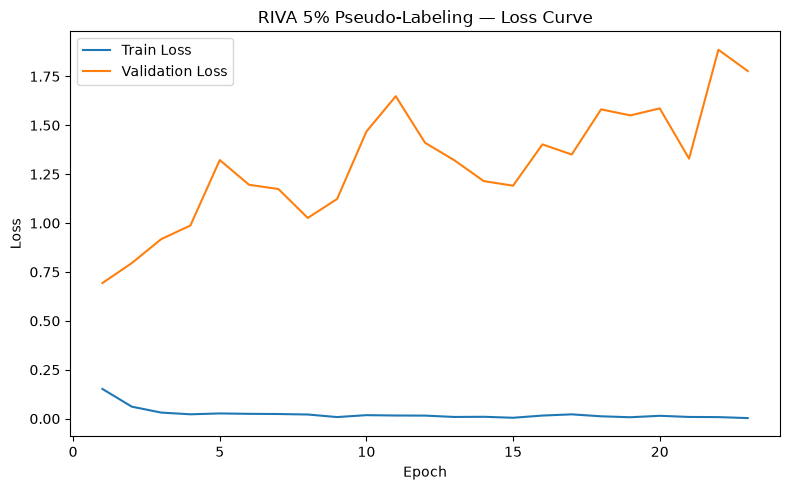

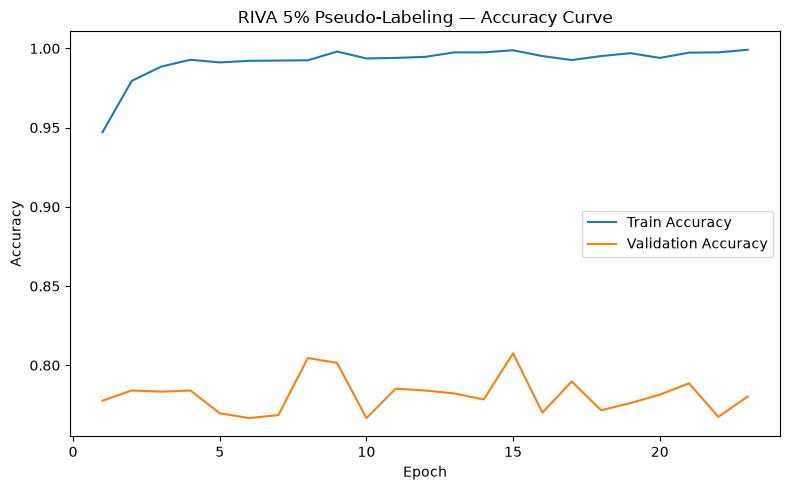

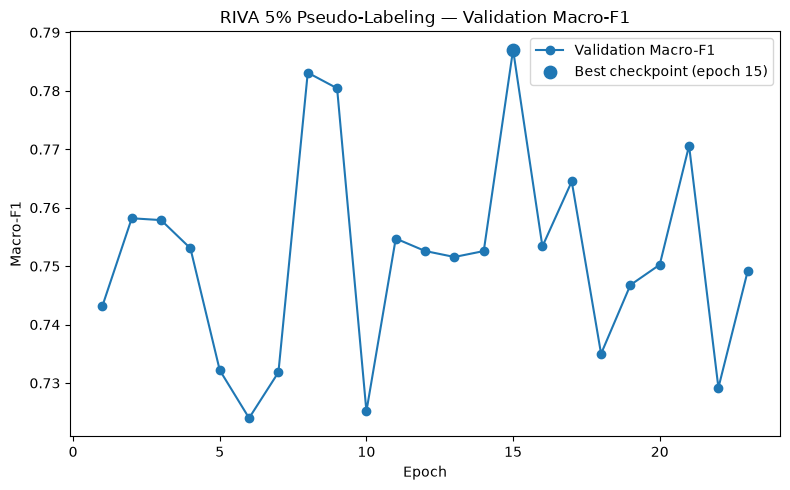

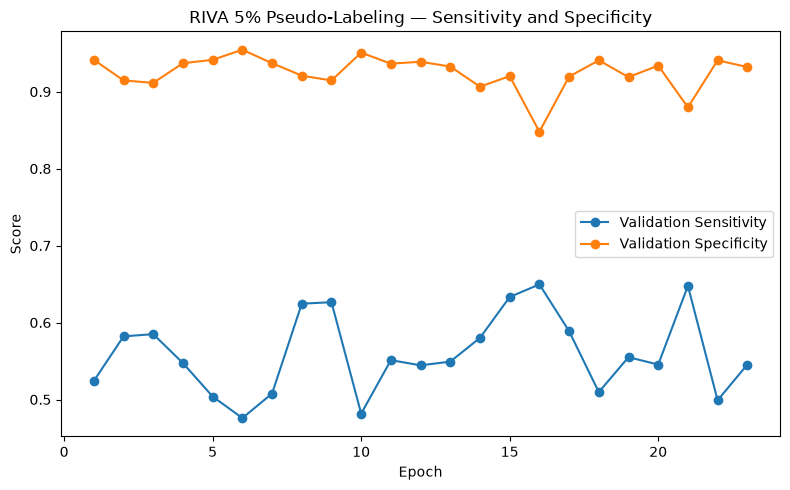


=== RIVA PHASE 13 ARTIFACTS SAVED ===
Epochs recorded: 23
Best epoch: 15
Best validation Macro-F1: 0.787029155815283

Saved artifacts:
experiment_id: riva_pseudolabel_5pct_densenet121_seed42
metrics: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase13\riva_pseudolabel_5pct_densenet121_seed42\metrics.json
comparison: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase13\riva_pseudolabel_5pct_densenet121_seed42\supervised_vs_pseudolabeling.csv
pseudo_label_statistics: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase13\riva_pseudolabel_5pct_densenet121_seed42\pseudo_label_statistics.json
training_history_csv: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase13\riva_pseudolabel_5pct_densenet121_seed42\training_history.csv
training_history_json: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase13\riva_pseudolabel_5pct_densenet121_seed42\training_history.json
loss_curve: c:\Users\nanda\Documents\cervical-semi-sl\data\results\phase13\riva

In [23]:
import matplotlib.pyplot as plt


curves_dir = (
    experiment_results_dir
    / "curves"
)


curves_dir.mkdir(
    parents=True,
    exist_ok=True
)


# --------------------------------------------------
# 1. Convert training history to DataFrame
# --------------------------------------------------

history_df = pd.DataFrame(
    semi_sl_history["history"]
)


print(
    "History shape:",
    history_df.shape
)

print(
    "History columns:"
)

print(
    list(history_df.columns)
)


# --------------------------------------------------
# 2. Save complete epoch-by-epoch history
# --------------------------------------------------

history_path = (
    experiment_results_dir
    / "training_history.csv"
)


history_df.to_csv(
    history_path,
    index=False
)


history_json_path = (
    experiment_results_dir
    / "training_history.json"
)


with open(
    history_json_path,
    "w"
) as f:

    json.dump(

        semi_sl_history,

        f,

        indent=4,

        default=float

    )


# --------------------------------------------------
# 3. Loss curve
# --------------------------------------------------

plt.figure(figsize=(8, 5))


plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)


plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)


plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title(
    "RIVA 5% Pseudo-Labeling — Loss Curve"
)

plt.legend()

plt.tight_layout()


loss_path = (
    curves_dir
    / "loss_curve.png"
)


plt.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# --------------------------------------------------
# 4. Accuracy curve
# --------------------------------------------------

plt.figure(figsize=(8, 5))


plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Train Accuracy"
)


plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation Accuracy"
)


plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title(
    "RIVA 5% Pseudo-Labeling — Accuracy Curve"
)

plt.legend()

plt.tight_layout()


accuracy_path = (
    curves_dir
    / "accuracy_curve.png"
)


plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# --------------------------------------------------
# 5. Validation Macro-F1 curve
# --------------------------------------------------

plt.figure(figsize=(8, 5))


plt.plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)


best_epoch = int(
    semi_sl_history["best_epoch"]
)


best_f1 = float(
    semi_sl_history["best_metric"]
)


plt.scatter(
    [best_epoch],
    [best_f1],
    s=80,
    label=(
        f"Best checkpoint "
        f"(epoch {best_epoch})"
    )
)


plt.xlabel("Epoch")

plt.ylabel("Macro-F1")

plt.title(
    "RIVA 5% Pseudo-Labeling — "
    "Validation Macro-F1"
)

plt.legend()

plt.tight_layout()


f1_path = (
    curves_dir
    / "macro_f1_curve.png"
)


plt.savefig(
    f1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# --------------------------------------------------
# 6. Sensitivity / Specificity curve
# --------------------------------------------------

plt.figure(figsize=(8, 5))


plt.plot(
    history_df["epoch"],
    history_df["val_sensitivity"],
    marker="o",
    label="Validation Sensitivity"
)


plt.plot(
    history_df["epoch"],
    history_df["val_specificity"],
    marker="o",
    label="Validation Specificity"
)


plt.xlabel("Epoch")

plt.ylabel("Score")

plt.title(
    "RIVA 5% Pseudo-Labeling — "
    "Sensitivity and Specificity"
)

plt.legend()

plt.tight_layout()


sens_spec_path = (

    curves_dir
    / "sensitivity_specificity_curve.png"

)


plt.savefig(
    sens_spec_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# --------------------------------------------------
# 7. Save artifact summary
# --------------------------------------------------

artifact_summary = {

    "experiment_id":
        experiment_id,

    "metrics":
        str(result_path),

    "comparison":
        str(comparison_path),

    "pseudo_label_statistics":
        str(pseudo_stats_path),

    "training_history_csv":
        str(history_path),

    "training_history_json":
        str(history_json_path),

    "loss_curve":
        str(loss_path),

    "accuracy_curve":
        str(accuracy_path),

    "macro_f1_curve":
        str(f1_path),

    "sensitivity_specificity_curve":
        str(sens_spec_path),

    "checkpoint":
        str(semi_sl_checkpoint),

}


artifact_summary_path = (

    experiment_results_dir
    / "artifact_summary.json"

)


with open(
    artifact_summary_path,
    "w"
) as f:

    json.dump(
        artifact_summary,
        f,
        indent=4
    )


print(
    "\n=== RIVA PHASE 13 ARTIFACTS SAVED ==="
)

print("=" * 50)

print(
    "Epochs recorded:",
    len(history_df)
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best validation Macro-F1:",
    best_f1
)


print("\nSaved artifacts:")

for name, path in artifact_summary.items():

    print(
        f"{name}: {path}"
    )